**Tugas Pendamping UTS SK5017 Sains dan Pengamanan Data**
  
Nama: Khoiro Amalia  |  NIM: 20925304

In [37]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, mean_squared_error, r2_score,
                             mean_absolute_error, silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score)
import statsmodels.api as sm
import os
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams["figure.dpi"] = 100

## Praprosses Data

Dataset Abalone dari UCI *Machine Learning Repository* berisi 4177 data pengamatan dengan 8 fitur yang terdiri dari satu fitur kategorik `Sex` (M = jantan, F = betina, I = *infant*) dan tujuh fitur numerik, yaitu `Length`, `Diameter`, `Height`, `Whole_weight`, `Shucked_weight`, `Viscera_weight`, `Shell_weight`. Fitur `Rings` adalah jumlah cincin pada cangkang dimana umur abalone kira-kira `Rings + 1,5` tahun.

In [38]:
#pemberian nama kolom
KOLOM = ["Sex", "Length", "Diameter", "Height", "Whole_weight",
"Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"]
FITUR_NUMERIK = KOLOM[1:-1]
SEED = 42

Data `abalone` dari UCI tidak memiliki baris judul, sehingga nama kolom ditulis manual mengikuti dokumentasi dataset. `FITUR_NUMERIK` berisi tujuh ukuran fisik (semua kolom kecuali `Sex` dan `Rings`). `SEED = 42` digunakan di setiap proses acak agar memperoleh hasil yang sama setiap kode dijalankan ulang.

In [39]:
def muat_data(path="abalone.data", bersihkan=True):
    df = pd.read_csv(path, header=None, names=KOLOM)
    if bersihkan:
        df = df[df["Height"] > 0].reset_index(drop=True)
    return df

Fungsi `muat_data` membaca berkas data dan memasang nama kolom. Bila `bersihkan=True`, baris dengan `Height` sama dengan 0 dibuang karena tinggi cangkang 0 mm tidak mungkin secara fisik dan diperlakukan sebagai kesalahan data.

In [40]:
muat_data()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...
4170,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4171,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4172,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4173,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


 Tabel diatas menampilkan isi baris awal dan akhir dengan sembilan kolom yang terdiri dari delapan fitur dan target `Rings` dengan jumlah baris yaitu 4175 setelah pembersihan.

In [41]:
#EDA
mentah = muat_data(bersihkan=False)
print("Bentuk data mentah:", mentah.shape, "| nilai kosong:", mentah.isna().sum().sum(), "| duplikat:", mentah.duplicated().sum())
print(mentah["Sex"].value_counts().to_string())
print("\nBaris dengan Height = 0:")
display(mentah[mentah["Height"] == 0])
df = muat_data()
print("\nSetelah pembersihan:", df.shape)
display(df[FITUR_NUMERIK + ["Rings"]].describe().T.round(3))
display(df[FITUR_NUMERIK + ["Rings"]].corr().round(2))

Bentuk data mentah: (4177, 9) | nilai kosong: 0 | duplikat: 0
Sex
M    1528
I    1342
F    1307

Baris dengan Height = 0:


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6



Setelah pembersihan: (4175, 9)


,count,mean,std,min,25%,50%,75%,max
Length,4175.0,0.524,0.120,0.075,0.450,0.545,0.615,0.815
Diameter,4175.0,0.408,0.099,0.055,0.350,0.425,0.480,0.650
Height,4175.0,0.140,0.042,0.010,0.115,0.140,0.165,1.130
Whole_weight,4175.0,0.829,0.490,0.002,0.442,0.800,1.154,2.826
Shucked_weight,4175.0,0.359,0.222,0.001,0.186,0.336,0.502,1.488
Viscera_weight,4175.0,0.181,0.110,0.000,0.094,0.171,0.253,0.760
Shell_weight,4175.0,0.239,0.139,0.002,0.130,0.234,0.329,1.005
Rings,4175.0,9.935,3.224,1.000,8.000,9.000,11.000,29.000


,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
Length,1.00,0.99,0.83,0.93,0.90,0.90,0.90,0.56
Diameter,0.99,1.00,0.83,0.93,0.89,0.90,0.91,0.57
Height,0.83,0.83,1.00,0.82,0.78,0.80,0.82,0.56
Whole_weight,0.93,0.93,0.82,1.00,0.97,0.97,0.96,0.54
Shucked_weight,0.90,0.89,0.78,0.97,1.00,0.93,0.88,0.42
Viscera_weight,0.90,0.90,0.80,0.97,0.93,1.00,0.91,0.50
Shell_weight,0.90,0.91,0.82,0.96,0.88,0.91,1.00,0.63
Rings,0.56,0.57,0.56,0.54,0.42,0.50,0.63,1.00


Setelah dilakukan eksplorasi awal data (*exploratory data analysis*). Data mentah berukuran 4177 baris tidak memiliki nilai kosong maupun duplikat, kemudian jumlah sebaran fitur `Sex` seimbang dengan M 1528, I 1342, dan F 1307. Ditemukan dua baris dengan `Height` = 0 yang ada pada kelas I, yang kemudian dibuang sehingga data tersisa 4175 baris. Statistik deskriptif menunjukkan satu nilai `Height` ekstrem (maksimum 1,13 sementara rata-ratanya sekitar 0,14). Matriks korelasi menunjukkan ketujuh fitur ukuran saling berkorelasi sangat kuat sekitar 0,78 sampai 0,99, sedangkan korelasinya dengan `Rings` hanya sekitar 0,4 sampai 0,6.

Hasil tersebut penting karena menjelaskan masalah multikolinearitas pada bagian regresi dan hasil klasterisasi yang didominasi satu dimensi ukuran.

## 1. Klasifikasi



In [42]:
df = muat_data()
X = df[FITUR_NUMERIK]
le = LabelEncoder()
y = le.fit_transform(df["Sex"])
nama_kelas = list(le.classes_)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_tr.shape, "Test:", X_te.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (3340, 7) Test: (835, 7)


Pada tahap klasifikasi, target yang digunakan adalah fitur 'sex' dengan tiga kelas yaitu F, I, dan M. Kelas pada fitur 'sex' kemudian dilakukan `LabelEncoder` menjadi F=0, I=1, M=2, sedangkan `X` hanya berisi tujuh fitur numerik. Data dibagi 80% untuk latih (3340 baris) dan 20% untuk uji (835 baris). Argumen `stratify=y` menjaga proporsi tiap kelas tetap sama di kedua bagian. Kemudian `StratifiedKFold` dengan 5 fold disiapkan untuk validasi silang saat mencari hiperparameter.

In [43]:
#SVM
pipe_svm = Pipeline([("scaler", StandardScaler()), ("clf", SVC(random_state=SEED))])
grid_svm = {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100, 1000],
            "clf__gamma": ["scale", 0.001, 0.01, 0.1, 1]}
gs_svm = GridSearchCV(pipe_svm, grid_svm, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_tr, y_tr)


Model pertama adalah SVM. Standarisasi dimasukkan ke dalam *pipeline* supaya rata-rata dan simpangan baku dihitung hanya dari data latih, sehingga tidak ada informasi data uji yang bocor ke model. Kernel RBF dipilih agar batas keputusan dapat melengkung. Parameter `C` mengatur seberapa besar kesalahan pada data latih ditoleransi, dan `gamma` mengatur seberapa jauh pengaruh satu titik data. `GridSearchCV` mencoba seluruh kombinasi keduanya dengan validasi silang 5 fold dan memilih yang memberikan akurasi tertinggi.

In [44]:
#RF
pipe_rf = Pipeline([("scaler", StandardScaler()), ("clf", RandomForestClassifier(random_state=SEED))])
grid_rf = {"clf__n_estimators": [200, 500], "clf__max_depth": [4, 6, 8, None],
           "clf__min_samples_leaf": [1, 5, 10]}
gs_rf = GridSearchCV(pipe_rf, grid_rf, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_tr, y_tr)

Model kedua adalah *Random Forest*. Pencarian grid diterapkan pada tiga hiperparameter, yaitu jumlah pohon (`n_estimators`), kedalaman maksimum pohon (`max_depth`), dan jumlah minimum sampel pada setiap daun (`min_samples_leaf`). Meskipun algoritma *Random Forest* tidak memerlukan standarisasi, tetapi tahapan *pipeline* yang sama tetap digunakan agar alur prapemrosesan dan evaluasi kedua model seragam.

In [45]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)

Model dasar (*Baseline*) dibuat menggunakan pendekatan sederhana yang selalu memprediksi kelas mayoritas pada data latih. Karena model ini tidak belajar apa pun dari fitur, sehingga tingkat akurasinya dijadikan patokan kinerja minimum. Dengan demikian, penerapan SVM dan Random Forest baru memiliki nilai tambah apabila menghasilkan akurasi yang lebih tinggi dibandingkan model dasar.

In [46]:
hasil, cm_dict = {}, {}
for nama, model in [("Baseline (kelas mayoritas)", dummy), ("SVM (RBF)", gs_svm.best_estimator_),
                    ("Random Forest", gs_rf.best_estimator_)]:
    pred = model.predict(X_te)
    hasil[nama] = {
        "accuracy": accuracy_score(y_te, pred),
        "precision_macro": precision_score(y_te, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_te, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_te, pred, average="macro", zero_division=0),
        "precision_per_kelas": dict(zip(nama_kelas, precision_score(y_te, pred, average=None, zero_division=0))),
        "recall_per_kelas": dict(zip(nama_kelas, recall_score(y_te, pred, average=None, zero_division=0))),
    }
    cm_dict[nama] = confusion_matrix(y_te, pred)
    print("\n==", nama)
    print(classification_report(y_te, pred, target_names=nama_kelas, zero_division=0, digits=3))

hasil["SVM (RBF)"]["param_terbaik"] = {k: str(v) for k, v in gs_svm.best_params_.items()}
hasil["SVM (RBF)"]["cv_accuracy"] = gs_svm.best_score_
hasil["Random Forest"]["param_terbaik"] = {k: str(v) for k, v in gs_rf.best_params_.items()}
hasil["Random Forest"]["cv_accuracy"] = gs_rf.best_score_
print("SVM best:", gs_svm.best_params_, round(gs_svm.best_score_, 4))
print("RF best:", gs_rf.best_params_, round(gs_rf.best_score_, 4))


== Baseline (kelas mayoritas)
              precision    recall  f1-score   support

           F      0.000     0.000     0.000       261
           I      0.000     0.000     0.000       268
           M      0.366     1.000     0.536       306

    accuracy                          0.366       835
   macro avg      0.122     0.333     0.179       835
weighted avg      0.134     0.366     0.197       835


== SVM (RBF)
              precision    recall  f1-score   support

           F      0.567     0.226     0.323       261
           I      0.660     0.832     0.736       268
           M      0.481     0.618     0.541       306

    accuracy                          0.564       835
   macro avg      0.569     0.559     0.533       835
weighted avg      0.565     0.564     0.535       835


== Random Forest
              precision    recall  f1-score   support

           F      0.500     0.345     0.408       261
           I      0.669     0.821     0.737       268
           M

Sel ini mengevaluasi ketiga model pada data uji dengan menghitung akurasi, presisi, *recall*, dan F1 (rata-rata *macro* dan per kelas), sekaligus menyusun confussion matrix, dan mencetak `classification_report`.

Hasil evaluasi menunjukkan akurasi uji SVM mencapai 0,564 dan *Random Forest* 0,562, keduanya melampaui akurasi model *baseline* yaitu 0,366. Selain itu, parameter terbaik hasil pencarian grid yaitu
- SVM: `C` = 100, `gamma` = 0,1
- RF: 500 pohon, tanpa batas kedalaman, `min_samples_leaf` = 10

Rincian per kelas menunjukkan bahwa nilai *recall* kelas I tergolong tinggi sekitar 0,82–0,83, sedangkan kelas F rendah sekitar 0,226 pada SVM dan 0,345 pada RF.

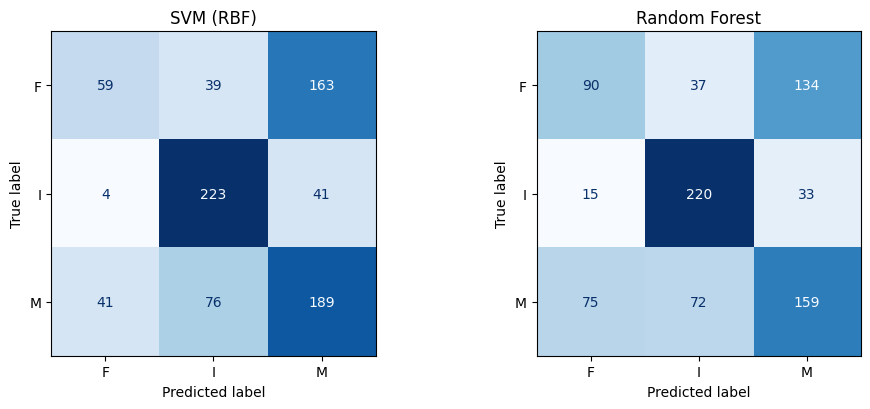

In [47]:
# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, nama in zip(axes, ["SVM (RBF)", "Random Forest"]):
    ConfusionMatrixDisplay(cm_dict[nama], display_labels=nama_kelas).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nama)
plt.tight_layout(); plt.savefig("figures/p1_confusion_matrix.png", dpi=150); plt.show()

Confussion Matrix untuk model SVM dan *Random Forest* divisualisasikan berdampingan. Baris menunjukkan kelas aktual, kolom menunjukkan hasil prediksi, dan angka pada diagonal menunjukkan jumlah prediksi yang benar. Berdasarkan gambar di atas, kelas I terlihat paling banyak terklasifikasi benar, sedangkan abalone F banyak diprediksi sebagai M. Karena hasil akurasi yang rendah yaitu hanya disekitar 56% serta masih banyak kesalahan prediksi pada kelas F dan M, maka akan dilakukan analisis tambahan pada sel-sel berikutnya.

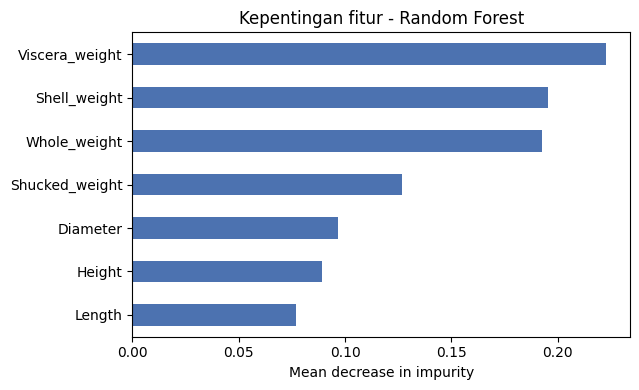

Viscera_weight    0.223
Shell_weight      0.195
Whole_weight      0.192
Shucked_weight    0.127
Diameter          0.097
Height            0.089
Length            0.077
dtype: float64


In [48]:
# Feature importance RF
rf = gs_rf.best_estimator_.named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=FITUR_NUMERIK).sort_values()
plt.figure(figsize=(6.5, 4)); imp.plot.barh(color="#4C72B0")
plt.xlabel("Mean decrease in impurity"); plt.title("Kepentingan fitur - Random Forest")
plt.tight_layout(); plt.savefig("figures/p1_rf_importance.png", dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(3))

Gambar diatas menampilkan tingkat kepentingan fitur  (*feature importance*) dari model *Random Forest* terbaik dalam bentuk diagram batang. Nilai ini diukur berdasarkan mean decrease in impurity, yaitu seberapa besar rata-rata pengurangan tingkat ketidakmurnian (impurity) oleh setiap fitur saat proses pemisahan cabang pohon berlangsung. Fitur teratas adalah `Viscera_weight` (0,223), `Shell_weight` (0,195), dan `Whole_weight` (0,192), sedangkan `Length` merupakan fitur terendah (0,077). Namun, karena seluruh fitur fisik saling berkorelasi kuat, bobot kepentingan terbagi di antara fitur yang serupa, sehingga urutannya tidak bisa dibaca sebagai fitur mana yang paling menentukan secara biologis.

In [49]:
# gabungkan F dan M menjadi 'dewasa' (I vs dewasa)
y_bin = (df["Sex"] != "I").astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X, y_bin, test_size=0.2, stratify=y_bin, random_state=SEED)
tambahan = {}
for nama, est in [("SVM (RBF)", gs_svm.best_estimator_), ("Random Forest", gs_rf.best_estimator_)]:
    m = clone(est).fit(Xb_tr, yb_tr)
    p = m.predict(Xb_te)
    tambahan[nama] = {"accuracy": accuracy_score(yb_te, p), "precision": precision_score(yb_te, p),
                      "recall": recall_score(yb_te, p)}
# Hanya F vs M
mask = (df["Sex"] != "I").values
Xfm, yfm = X[mask], (df["Sex"][mask] == "M").astype(int)
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xfm, yfm, test_size=0.2, stratify=yfm, random_state=SEED)
for nama, est in [("SVM (RBF)", gs_svm.best_estimator_), ("Random Forest", gs_rf.best_estimator_)]:
    p = clone(est).fit(Xf_tr, yf_tr).predict(Xf_te)
    tambahan[nama + " | F vs M saja"] = {"accuracy": accuracy_score(yf_te, p)}
print("\nEksperimen tambahan:", json.dumps(tambahan, indent=1))

json.dump({"hasil": hasil, "tambahan": tambahan, "confusion": {k: v.tolist() for k, v in cm_dict.items()},
           "importance": imp.to_dict(), "n_train": len(X_tr), "n_test": len(X_te)},
          open("results/part1.json", "w"), indent=2, default=float)


Eksperimen tambahan: {
 "SVM (RBF)": {
  "accuracy": 0.8323353293413174,
  "precision": 0.8700173310225303,
  "recall": 0.8853615520282186
 },
 "Random Forest": {
  "accuracy": 0.8323353293413174,
  "precision": 0.8739054290718039,
  "recall": 0.8800705467372134
 },
 "SVM (RBF) | F vs M saja": {
  "accuracy": 0.564373897707231
 },
 "Random Forest | F vs M saja": {
  "accuracy": 0.5308641975308642
 }
}


Analisis tambahan dilakukan untuk menelusuri penyebab rendahnya akurasi model, yaitu:
1. Kelas F dan M digabung menjadi "dewasa" sehingga tugasnya menjadi klasifikasi biner antara *infant* dan dewasa.
2. Hanya abalone dewasa yang dipakai untuk membedakan F dari M.

Kedua percobaan memakai model dan hiperparameter terbaik dari model utama dan dilatih dengan pembagian data baru. Hasil pengujian menunjukkan bahwa akurasi klasifikasi infant lawan dewasa meningkat menjadi 0,832 pada kedua model, sedangkan klasifikasi F dan M hanya mencapai 0,564 (SVM) dan 0,531 (Random Forest). Hasil tersebut menegaskan bahwa fitur ukuran fisik memadai untuk membedakan fase pertumbuhan, tetapi hampir tidak mampu memisahkan jenis kelamin jantan dan betina.

### Pembahasan

Kedua model memiliki akurasi yang mirip yaitu 0,564 untuk SVM dan 0,562 untuk RF, tetapi jauh di atas akurasi model sederhana yang dijadikan patokan minimum akurasi yaitu 0,366.

Pada 835 data uji, SVM sedikit unggul pada akurasi, presisi *macro*, dan akurasi validasi silang yaitu 0,554 berbanding 0,546, sedangkan RF sedikit unggul pada *recall* dan F1 *macro* karena lebih sering berhasil mengenali kelas F.


Jika dianalisis dari pola kesalahannya, kedua model mampu mengenali kelas I dengan baik (*recall* sekitar 0,82–0,83), tetapi sering kali tertukar dalam membedakan kelas F dan M. Pada SVM, *Recall* untuk kelas F hanya 0,226 dari 261 abalone betina, sebanyak 163 diantaranya salah diprediksi sebagai jantan. Oleh karena itu, untuk memastikan hal ini dijalankan dua eksperimen tambahan dengan model dan hiperparameter yang sama.

Pada klasifikasi biner antara *infant* dan dewasa (F dan M digabung), akurasi kedua model naik menjadi 0,832 (presisi 0,870 dan 0,874, serta *recall* 0,885 dan 0,880 untuk kelas dewasa). Sebaliknya, ketika hanya membedakan kelas F dan M, akurasi menurun menjadi 0,564 (SVM) dan 0,531 (RF).
Hal ini menunjukkan bahwa fitur fisik hampir tidak dapat membedakan jantan dan betina, informasi yang dapat dipelajari model hanyalan perbedaan fase pertumbuhan antara fase *infant* yang berukuran kecil dan fase dewasa yang berukuran besar. Dengan demikian, batas kinerja sekitar 56% lebih disebabkan oleh keterbatasan karakteristik data dibanding pemilihan algoritma model.

Dari sisi kelebihan dan kekurangan, SVM dengan kernel RBF mampu membentuk batas keputusan non-linier yang halus dan bekerja efektif pada fitur kontinu yang berdimensi rendah.Tetapi metode ini sensitif terhadap skala fitur sehingga memerlukan tahap standarisasi, membutuhkan penyetelan parameter `C` dan `gamma`, serta tidak memberikan inf0rmasi feature importance. Di sisi lain, tingginya korelasi antarfitur abalone tidak menjadi kendala multikolinearitas pada SVM, meskipun sebagian besar informasi tersebut sebenarnya hanya merepresentasikan satu dimensi yaitu "ukuran".

Sementara itu, *Random Forest* tidak memerlukan standarisasi data, lebih tahan terhadap pencilan, dan mampu mengukur feature importance. Namun, korelasi fitur yang tinggi membuat bobot kepentingan terbagi. RF juga cenderung mengalami *overfitting* apabila nilai `min_samples_leaf` terlalu kecil.

## 2. Regresi jumlah cincin


In [50]:
df = muat_data()
y = df["Rings"]
X = df.drop(columns="Rings")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
print("Train:", X_tr.shape, "Test:", X_te.shape)

Train: (3340, 8) Test: (835, 8)


Pada tahap regresi, target yang digunakan adalah fitur 'Rings' untuk mewakili usia abalone, sedangkan matriks fitur `X` memuat semua fitur termasuk `Sex` yang nantinya akan dikoncersi menjadi variabel *dummy* pada tahap prapemrosesan. Dataset kemudian dibagi menjadi data latih dan data uji dengan perbandingan  80:20 dengan `random_state` yang sama seperti Bagian 1 tanpa melakukan stratifikasi karena target bersifat numerik. Kemudian menyiapkan `KFold` 5 untuk validasi silang.

In [51]:
#cek korelasi fitur pada rings untuk memilih prediktor regresi sederhana
kor = X_tr[FITUR_NUMERIK].corrwith(y_tr).sort_values(ascending=False)
print(kor.round(3))
fitur_sederhana = kor.index[0]
print("Prediktor regresi linear sederhana:", fitur_sederhana)

Shell_weight      0.626
Diameter          0.575
Length            0.557
Height            0.550
Whole_weight      0.543
Viscera_weight    0.510
Shucked_weight    0.425
dtype: float64
Prediktor regresi linear sederhana: Shell_weight


Karena pemodelan regresi linear sederhana hanya menggunakan satu variabel prediktor. Korelasi tiap fitur numerik hanya diterapkan terhadap `Rings` pada data latih, fitur dengan korelasi tertinggi yaitu `Shell_weight` dengan r = 0,626. Penghitungan dibatasi hanya pada data latih untuk mencegah kebocoran data (data leakage), sehingga data uji tidak memengaruhi proses pemilihan fitur.

In [52]:
num_pre = lambda cols: ColumnTransformer([("num", StandardScaler(), cols)])
prep_semua = ColumnTransformer([("num", StandardScaler(), FITUR_NUMERIK),
                                ("cat", OneHotEncoder(drop="first"), ["Sex"])])

model = {
    "Regresi Linear Sederhana": Pipeline([("pre", num_pre([fitur_sederhana])), ("reg", LinearRegression())]),
    "Regresi Linear Berganda": Pipeline([("pre", prep_semua), ("reg", LinearRegression())]),
    "Regresi Polinomial (derajat 2, Ridge)": Pipeline([("pre", prep_semua),
                         ("poly", PolynomialFeatures(2, include_bias=False)),
                         ("sc", StandardScaler()), ("reg", Ridge(alpha=10))]),
    "Random Forest Regressor": Pipeline([("pre", prep_semua),
                         ("reg", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
}
gs = GridSearchCV(model["Regresi Polinomial (derajat 2, Ridge)"], {"reg__alpha": [0.1, 1, 10, 100, 1000]},
                  cv=kf, scoring="neg_mean_squared_error").fit(X_tr, y_tr)
model["Regresi Polinomial (derajat 2, Ridge)"] = gs.best_estimator_
print("alpha Ridge terbaik:", gs.best_params_)

alpha Ridge terbaik: {'reg__alpha': 1000}


Empat model regresi yang akan dibandingkan yaitu:
1. Regresi linear sederhana dengan satu fitur yaitu `Shell_weight`.
2. Regresi linear berganda dengan tujuh fitur numerik yang sudah distandardisasi beserta fitur `Sex` yang sudah dilakukan *one-hot encoding*.
3. Regresi polinomial derajat 2 dengan regularisasi Ridge untuk mengendalikan banyaknya suku interaksi.
4. *Random Forest Regressor* sebagai pembanding non-linier.

Nilai parammeter pinalti `alpha` pada Ridge ditentukan melalui validasi silang pada data latih dan menghasilkan nilai optimal 1000, karena berada tepat di batas atas rentang grid.

In [53]:
hasil, pred = {}, {}
for nama, m in model.items():
    cv_mse = -cross_val_score(clone(m), X_tr, y_tr, cv=kf, scoring="neg_mean_squared_error")
    m.fit(X_tr, y_tr)
    p = m.predict(X_te); pred[nama] = p
    hasil[nama] = {"MSE_uji": mean_squared_error(y_te, p), "RMSE_uji": mean_squared_error(y_te, p) ** 0.5,
                   "MAE_uji": mean_absolute_error(y_te, p), "R2_uji": r2_score(y_te, p),
                   "MSE_latih": mean_squared_error(y_tr, m.predict(X_tr)),
                   "MSE_CV5": cv_mse.mean(), "SD_CV5": cv_mse.std()}
    print(f"{nama:42s} MSE uji={hasil[nama]['MSE_uji']:.3f}  RMSE={hasil[nama]['RMSE_uji']:.3f}  "
          f"MAE={hasil[nama]['MAE_uji']:.3f}  R2={hasil[nama]['R2_uji']:.3f}  MSE CV={cv_mse.mean():.3f}+-{cv_mse.std():.3f}")

Regresi Linear Sederhana                   MSE uji=6.841  RMSE=2.615  MAE=1.903  R2=0.401  MSE CV=6.167+-0.500
Regresi Linear Berganda                    MSE uji=4.911  RMSE=2.216  MAE=1.591  R2=0.570  MSE CV=4.972+-0.495
Regresi Polinomial (derajat 2, Ridge)      MSE uji=5.901  RMSE=2.429  MAE=1.705  R2=0.483  MSE CV=5.482+-0.578
Random Forest Regressor                    MSE uji=4.942  RMSE=2.223  MAE=1.552  R2=0.567  MSE CV=4.637+-0.422


Setiap model kemudian dilatih dan dievaluasi menggunakan skema validasi silang dan pengujian akhir. Skor MSE validasi silang 5 fold dievaluasi terlebih dahulu pada himpunan data latih untuk mengukur kestabilan model. Kemudian, setiap model dilatih menggunakan keseluruhan data latih untuk mengukur kinerja generalisasi pada data uji melalui metrik MSE, RMSE, MAE, dan R^2, disertai penghitungan MSE latih guna mengidentifikasi potensi overfitting.

Berdasarkan perbandingan metrik evaluasi, regresi linear berganda memperoleh MSE uji paling rendah (4,911), sedikit lebih baik dibandingkan Random Forest (4,942), sedangkan regresi polinomial (5,901) dan regresi linear sederhana (6,841) menghasilkan galat yang lebih besar.

In [54]:
#Prediksi Rings
tabel_pred = pd.DataFrame({"Rings aktual": y_te.values})
for nama, p in pred.items():
    tabel_pred[nama] = np.round(p, 2)
tabel_pred.index = X_te.index
print("10 contoh pertama data uji:")
print(tabel_pred.head(10).to_string())
tabel_pred.to_csv("results/prediksi_rings_data_uji.csv")

contoh = pd.DataFrame([{"Sex": "M", "Length": 0.55, "Diameter": 0.43, "Height": 0.15,
                        "Whole_weight": 0.80, "Shucked_weight": 0.35, "Viscera_weight": 0.18,
                        "Shell_weight": 0.25}])[X_tr.columns]
print("\nPrediksi Rings untuk contoh abalone baru:")
for nama, m in model.items():
    print(f"  {nama:42s} {m.predict(contoh)[0]:.2f}")

10 contoh pertama data uji:
      Rings aktual  Regresi Linear Sederhana  Regresi Linear Berganda  Regresi Polinomial (derajat 2, Ridge)  Random Forest Regressor
2330            15                     11.31                    13.31                                  11.92                    12.97
2411             7                      7.19                     7.90                                   8.02                     8.41
2195            11                      7.50                     7.32                                   6.95                     6.73
2381            11                      9.59                     9.66                                  10.02                     9.31
3571             9                     10.72                    10.32                                  10.95                    11.20
2428             9                      7.50                     8.15                                   8.22                     8.69
1983            11                

Hasil prediksi jumlah cincin ditampilkan dalam dua bentuk demonstrasi. Tabel pertama membandingkan `Rings` aktual dengan prediksi keempat model untuk 10 data uji pertama, dan seluruh prediksi data uji disimpan ke berkas CSV. Bagian kedua memprediksi satu abalone baru dengan ukuran contoh yang dibuat sendiri sebagai ilustrasi (bukan data nyata), dan keempat model memberi prediksi sekitar 10 sampai 11 cincin.

In [55]:
mse_base = mean_squared_error(y_te, np.full(len(y_te), y_tr.mean()))
hasil["Baseline (rata-rata)"] = {"MSE_uji": mse_base}
print("Baseline MSE:", round(mse_base, 3))

Baseline MSE: 11.411


Sebagai pembanding untuk regresi, dihitung MSE dari model yang selalu memprediksi rata-rata `Rings` data latih. Model sederhana ini menghasilkan MSE sebesar 11,41, sehingga membuktikan bahwa keempat model berhasil menurunkan galat prediksi.

In [56]:
#OLS pada data latih
Xs = pd.get_dummies(X_tr, columns=["Sex"], drop_first=True).astype(float)
ols = sm.OLS(y_tr.astype(float), sm.add_constant(Xs)).fit()
print(ols.summary().tables[1])

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.8447      0.328     11.728      0.000       3.202       4.487
Length            -1.4411      2.078     -0.693      0.488      -5.516       2.634
Diameter          12.4747      2.548      4.896      0.000       7.479      17.471
Height            10.4228      1.616      6.449      0.000       7.254      13.591
Whole_weight       7.8659      0.803      9.801      0.000       6.292       9.440
Shucked_weight   -18.6872      0.903    -20.696      0.000     -20.458     -16.917
Viscera_weight    -8.3759      1.436     -5.831      0.000     -11.192      -5.559
Shell_weight       9.2264      1.263      7.305      0.000       6.750      11.703
Sex_I             -0.7534      0.113     -6.671      0.000      -0.975      -0.532
Sex_M              0.1024      0.093      1.100      0.272      -0.080       0.285


Model regresi linear berganda dibangun ulang menggunakan pustaka *statsmodels* (OLS) pada data latih dalam skala asli untuk memperoleh nilai *p-value* serta selang kepercayaan koefisien.

Ringkasan Hasil Estimasi:
- Length: Tidak berpengaruh signifikan ($p = 0,488$).
- Shucked_weight & Viscera_weight: Memiliki koefisien bertanda negatif, meskipun secara biologis bobot tubuh yang lebih besar berasosiasi dengan usia yang lebih tua.
- Sex_I: Bernilai sekitar $-0,75$ dan signifikan secara statistik.
- Sex_M: Tidak signifikan ($p = 0,272$).

Kemunculan tanda koefisien yang tampak berlawanan dengan intuisi biologis mengindikasikan adanya gejala multikolinearitas antarfitur, yang akan diuji lebih lanjut pada sel berikutnya.

In [57]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(X_tr[FITUR_NUMERIK])
vif = {c: variance_inflation_factor(Xv.values, i) for i, c in enumerate(Xv.columns) if c != "const"}
print("VIF:", {k: round(v, 1) for k, v in vif.items()})

VIF: {'Length': np.float64(42.5), 'Diameter': np.float64(43.4), 'Height': np.float64(3.3), 'Whole_weight': np.float64(107.2), 'Shucked_weight': np.float64(27.5), 'Viscera_weight': np.float64(17.1), 'Shell_weight': np.float64(21.4)}


*variance inflation factor* (VIF) dihitung untuk mengukur multikolinearitas antarfitur, yaitu seberapa besar suatu fitur dapat diprediksi dari fitur lain. Nilai VIF di atas 10 mengindikasikan multikolinearitas yang tinggi. Hasilnya fitur `Whole_weight` mencapai sekitar 107, `Diameter` 43, `Length` 42,5, dan `Shucked_weight` 27,5, sedangkan `Height` hanya 3,3. Tingginya nilai VIF pada hampir seluruh fitur fisik (kecuali `Height`) menyebabkan estimasi koefisien pada regresi berganda menjadi tidak stabil dan sulit diinterpretasikan secara individual meskipun daya prediksi model secara keseluruhan tetap baik.

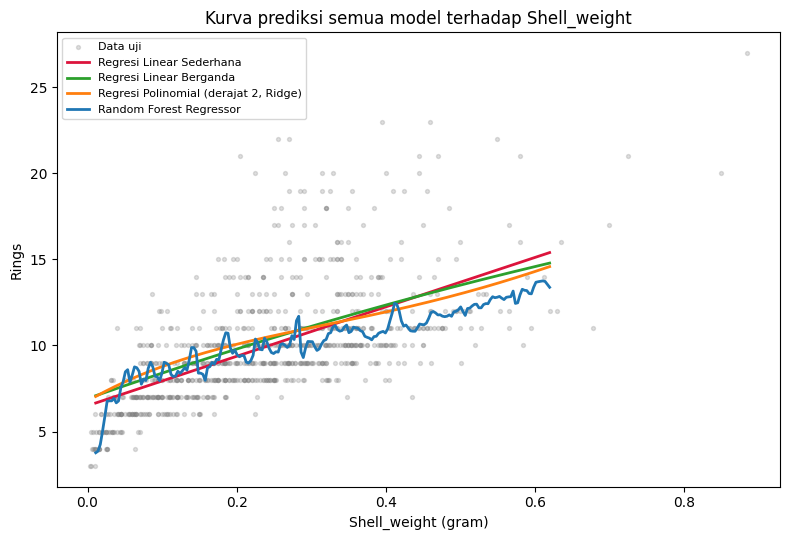

In [58]:
# scatter Rings
grid_sw = np.linspace(X_tr[fitur_sederhana].quantile(0.01), X_tr[fitur_sederhana].quantile(0.99), 200)
g_all = pd.DataFrame({fitur_sederhana: grid_sw})
for f in FITUR_NUMERIK:
    if f != fitur_sederhana:
        koef = np.polyfit(X_tr[fitur_sederhana], X_tr[f], deg=2)
        g_all[f] = np.polyval(koef, grid_sw)
g_all["Sex"] = X_tr["Sex"].mode()[0]
g_all = g_all[X_tr.columns]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(X_te[fitur_sederhana], y_te, s=8, alpha=0.25, color="grey", label="Data uji")
warna = ["crimson", "#2ca02c", "#ff7f0e", "#1f77b4"]
for (nama, m), w in zip(model.items(), warna):
    ax.plot(grid_sw, m.predict(g_all), lw=2, color=w, label=nama)
ax.set_xlabel(fitur_sederhana + " (gram)"); ax.set_ylabel("Rings")
ax.set_title("Kurva prediksi semua model terhadap " + fitur_sederhana); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/p2_scatter_semua_model.png", dpi=150); plt.show()

Gambar diatas adalah *scatter plot* `Rings` terhadap `Shell_weight` dari data uji, dengan kurva prediksi dari keempat model. Rentang bobot dibatasi pada persentil 1 sampai 99 untuk menghindari ekstrapolasi di luar sebaran data. Secara visual, kurva prediksi keempat model hampir berimpit, dengan model polinomial dan *Random Forest* cenderung melandai pada bobot cangkang yang besar. Namun, titik-titik observasi tetap menyebar lebar di sekitar kurva, yang menegaskan bahwa satu fitur prediktor saja belum memadai untuk memprediksi usia abalone secara akurat.

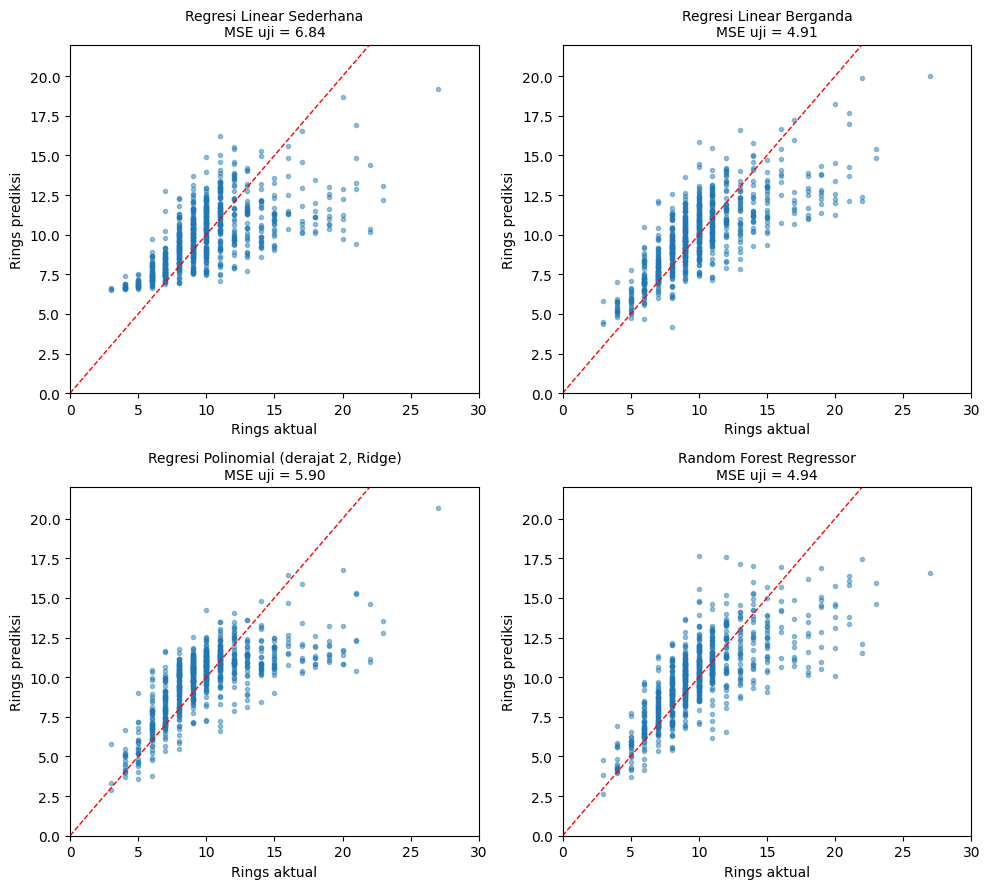

In [59]:
#aktual vs prediksi pada semua model
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (nama, p) in zip(axes.ravel(), pred.items()):
    ax.scatter(y_te, p, s=9, alpha=0.45)
    lim = [0, 30]; ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlim(lim); ax.set_ylim(0, 22)
    ax.set_title(f"{nama}\nMSE uji = {hasil[nama]['MSE_uji']:.2f}", fontsize=10)
    ax.set_xlabel("Rings aktual"); ax.set_ylabel("Rings prediksi")
plt.tight_layout(); plt.savefig("figures/p2_actual_vs_pred.png", dpi=150); plt.show()

Gambar diatas menampilkan plot perbandingan nilai aktual terhadap prediksi untuk keempat model. Garis putus-putus merah (diagonal) adalah prediksi sempurna, sehingga makin rapat titik ke diagonal makin baik modelnya. Secara keseluruhan, semua model cenderung menghasilkan prediksi yang terlalu rendah (underpredict) untuk abalone dengan jumlah cincin yang banyak, sebagaimana terlihat dari posisi titik-titik di sisi kanan yang mayoritas berada di bawah garis diagonal.

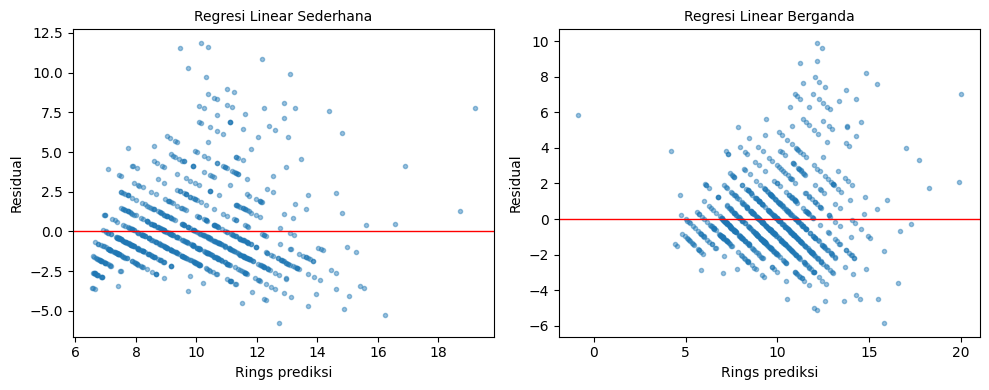

In [60]:
#residual SLR vs MLR
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nama in zip(axes, ["Regresi Linear Sederhana", "Regresi Linear Berganda"]):
    res = y_te - pred[nama]
    ax.scatter(pred[nama], res, s=9, alpha=0.45); ax.axhline(0, color="r", lw=1)
    ax.set_xlabel("Rings prediksi"); ax.set_ylabel("Residual"); ax.set_title(nama, fontsize=10)
plt.tight_layout(); plt.savefig("figures/p2_residuals.png", dpi=150); plt.show()

Gambar diatas menampilkan plot residual yaitu selisih antara aktual dan prediksi untuk model regresi sederhana dan regresi berganda. Titik yang tersebar acak di sekitar garis nol menandakan terpenuhinya asumsi regresi linear. Namun, terlihat bahwa residual tersusun dalam pola pita diagonal akibat target Rings yang bernilai bilangan bulat. Selain itu, sebarannya cenderung condong ke arah positif (mengindikasikan bahwa abalone tua kerap diprediksi terlalu muda) serta melebar pada rentang prediksi menengah ke atas, sehingga asumsi kehomogenan ragam (homoscedasticity) tidak terpenuhi sepenuhnya. Meskipun demikian, rentang sebaran galat pada regresi berganda tampak lebih sempit dibandingkan regresi sederhana.

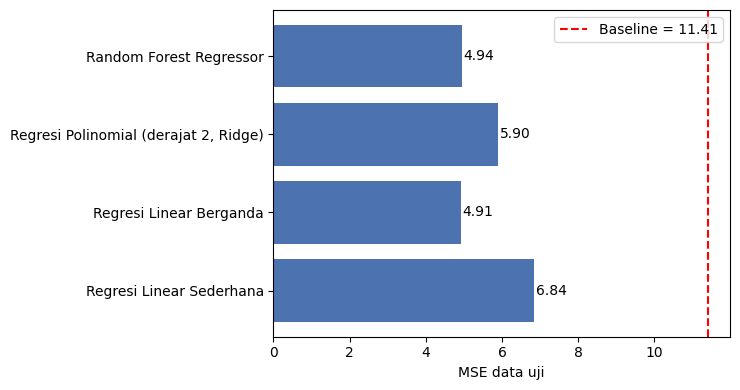

In [61]:
#perbandingan MSE
fig, ax = plt.subplots(figsize=(7.5, 4))
nm = [k for k in hasil if k != "Baseline (rata-rata)"]
ax.barh(nm, [hasil[k]["MSE_uji"] for k in nm], color="#4C72B0")
ax.axvline(mse_base, color="r", ls="--", label=f"Baseline = {mse_base:.2f}")
for i, k in enumerate(nm): ax.text(hasil[k]["MSE_uji"] + 0.05, i, f"{hasil[k]['MSE_uji']:.2f}", va="center")
ax.set_xlabel("MSE data uji"); ax.legend(); plt.tight_layout()
plt.savefig("figures/p2_mse_bar.png", dpi=150); plt.show()

Diagram batang di atas membandingkan nilai MSE pada data uji untuk seluruh model, dengan garis putus-putus merah yang menandai ambang batas model dasar (baseline). Seluruh model yang diuji mencatatkan nilai MSE jauh di bawah garis baseline tersebut, dengan regresi linear berganda dan Random Forest meraih galat terendah.

In [62]:
# Koefisien SLR pada skala asli
slr_raw = LinearRegression().fit(X_tr[[fitur_sederhana]], y_tr)
print(f"Rings = {slr_raw.intercept_:.2f} + {slr_raw.coef_[0]:.2f} x {fitur_sederhana}")

Rings = 6.50 + 14.35 x Shell_weight


Melatih ulang regresi sederhana pada skala asli dan mencetak persamaannya, yang berarti setiap tambahan 1 gram bobot cangkang dikaitkan dengan sekitar 14 cincin lebih banyak.

### Pembahasan

Regresi linear berganda menunjukkan kinerja yang lebih baik daripada regresi sederhana, yaitu ditandai dengan penurunan MSE uji dari 6,84 menjadi 4,91, dan R² naik dari 0,40 menjadi 0,57. Ketiga ukuran (MSE uji, MSE validasi silang, dan MAE) menunjukkan peringkat kinerja yang sama, jadi kesimpulan ini tidak bergantung pada skema satu pembagian data tertentu. Nilai MSE uji regresi sederhana yaitu 6,84 sedikit lebih tinggi daripada MSE validasi silang yaitu 6,17. Hal tersebut menunjukkan bahwa data uji kebetulan sedikit lebih sulit di prediksi, bukan karena model mengalami *overfitting*.

Visualisasi garis regresi sederhana pada scatter plot memperlihatkan keterbatasan Shell_weight dalam menangkap pola data, karena hubungannya dengan Rings melengkung—pada abalone tua, bobot cangkang terus bertambah sementara pertambahan cincinnya melambat.

Sementara itu, plot residual mengungkap dua hal, yaitu pola pita diagonal akibat target Rings yang berupa bilangan bulat, serta sebaran yang tidak simetris dan melebar pada prediksi menengah ke atas. Hal tersebut menunjukkan bahwa abalone tua cenderung diprediksi terlalu muda sehingga asumsi ragam konstan tidak terpenuhi. Pola serupa juga terlihat pada regresi berganda, meskipun dengan sebaran galat yang lebih sempit.
Pada regresi linear berganda, penafsiran koefisien OLS memerlukan kehati-hatian karena tingginya multikolinearitas antarfitur fisik. Akibatnya, estimasi koefisien individual menjadi tidak stabil meskipun daya prediksi model secara keseluruhan tetap baik. Regresi polinomial derajat 2 justru menghasilkan MSE uji lebih buruk (5,90). Sementara itu, Random Forest menghasilkan MSE uji yang setara dengan regresi berganda (4,94 berbanding 4,91), tetapi MSE latih yang dihasilkan sangat rendah (1,52) sehingga mengindikasikan terjadi overfitting.

Kesimpulannya, regresi linear berganda merupakan model yang memberikan hasil terbaik karena paling sederhana dengan galat terendah, meski memiliki keterbatasan pada interpretasi koefisien dan pelanggaran asumsi ragam konstan.

## 3. Clustering



In [63]:
df = muat_data()
X = StandardScaler().fit_transform(df[FITUR_NUMERIK])   # hanya 7 fitur fisik; Sex dan Rings TIDAK dipakai
n = len(X)
pca = PCA(n_components=2, random_state=SEED).fit(X)
Z = pca.transform(X)
pca_full = PCA().fit(X)
print("Varians PCA:", pca_full.explained_variance_ratio_.round(3))

Varians PCA: [0.908 0.04  0.024 0.016 0.009 0.002 0.001]


Pada tahap clustering, hanya tujuh fitur fisik yang dipakai dan distandarisasi, karena clustering bersifat tak terawasi sehingga `Sex` dan `Rings` tidak bisa dilibatkan. PCA dengan dua komponen diterapkan untuk memvisualisasikan klaster pada bidang dua dimensi, sedangkan PCA penuh digunakan untuk mengevaluasi porsi ragam tiap komponen. Hasilnya menunjukkan bahwa komponen pertama saja sudah mampu menjelaskan 90,8% total ragam data, artinya variasi dalam dataset pada dasarnya berbentuk didominasi oleh satu dimensi utama yaitu "ukuran" fisik.

In [64]:
K = range(2, 11)
def buat(nama, k):
    if nama == "K-means":
        return KMeans(n_clusters=k, n_init=20, random_state=SEED)
    if nama == "Spectral":
        return SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=15,
                                  assign_labels="kmeans", random_state=SEED)
    return AgglomerativeClustering(n_clusters=k, linkage="ward")

metrik, label = {}, {}
for nama in ["K-means", "Spectral", "Hierarchical (Ward)"]:
    key = nama if nama != "Hierarchical (Ward)" else "Hierarchical"
    metrik[nama] = {"k": [], "silhouette": [], "CH": [], "DB": []}
    for k in K:
        lab = buat(key, k).fit_predict(X)
        label[(nama, k)] = lab
        metrik[nama]["k"].append(k)
        metrik[nama]["silhouette"].append(silhouette_score(X, lab))
        metrik[nama]["CH"].append(calinski_harabasz_score(X, lab))
        metrik[nama]["DB"].append(davies_bouldin_score(X, lab))
    print(nama); print(pd.DataFrame(metrik[nama]).round(3).to_string(index=False))

K-means
 k  silhouette       CH    DB
 2       0.513 6497.275 0.669
 3       0.443 6601.457 0.725
 4       0.416 6627.087 0.764
 5       0.387 6470.528 0.819
 6       0.388 6080.162 0.684
 7       0.361 6022.759 0.714
 8       0.342 6003.896 0.792
 9       0.318 5862.875 0.837
10       0.296 5682.453 0.938
Spectral
 k  silhouette       CH    DB
 2       0.446 3592.262 0.595
 3       0.427 4410.280 0.629
 4       0.401 4683.729 0.664
 5       0.387 5062.651 0.700
 6       0.368 4627.230 0.718
 7       0.356 4872.029 0.762
 8       0.331 4655.448 0.811
 9       0.308 4236.826 0.853
10       0.295 4232.157 0.902
Hierarchical (Ward)
 k  silhouette       CH    DB
 2       0.513 6431.842 0.665
 3       0.452 5423.676 0.734
 4       0.390 5863.564 0.723
 5       0.364 6125.835 0.859
 6       0.365 5721.227 0.721
 7       0.323 5594.434 0.738
 8       0.314 5429.809 0.790
 9       0.272 5172.883 0.871
10       0.234 5004.001 1.049


Tiga algoritma clustering yaitu *K-means*, *Spectral Clustering* (graf 15 tetangga terdekat), dan *Hierarchical Clustering* dengan *linkage* Ward, dijalankan untuk k = 2 sampai 10. Setiap konfigurasi klaster dihitung tiga metrik validasi untuk mengukur kualitas pemisahan:
- *silhouette* (makin besar makin baik)
- Calinski-Harabasz (makin besar makin baik)
- Davies-Bouldin (makin kecil makin baik)

Hasil pengujian menunjukkan skor *silhouette* tertinggi dicapai pada k = 2 untuk ketiga algoritma (0,513 untuk K-means dan Ward, 0,446 untuk Spectral) dan menurun seiring bertambahnya nilai k.

In [65]:
inertia = [KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X).inertia_ for k in K]

Inersia *K-means* (jumlah kuadrat jarak titik ke pusat klasternya) dihitung untuk setiap k pada rentang yang sama, nantinya nilainya digunakan untuk metode siku (*elbow*) pada visualisasi berikutnya.

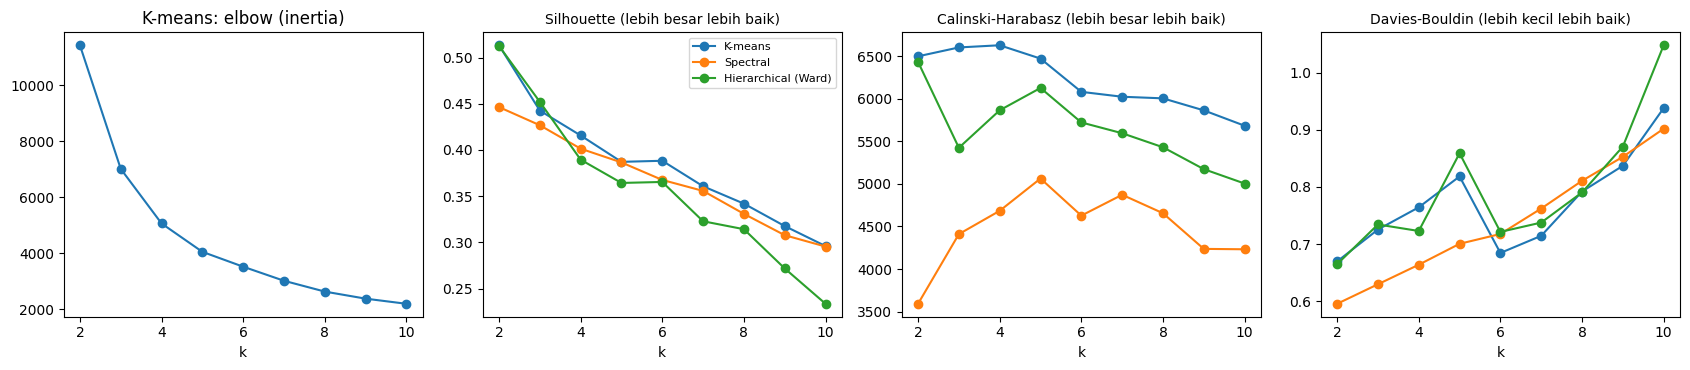

In [66]:
# elbow + metrik validasi
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].plot(list(K), inertia, "o-"); axes[0].set_title("K-means: elbow (inertia)"); axes[0].set_xlabel("k")
for nama, m in metrik.items():
    axes[1].plot(m["k"], m["silhouette"], "o-", label=nama)
    axes[2].plot(m["k"], m["CH"], "o-", label=nama)
    axes[3].plot(m["k"], m["DB"], "o-", label=nama)
for ax, t in zip(axes[1:], ["Silhouette (lebih besar lebih baik)", "Calinski-Harabasz (lebih besar lebih baik)",
                              "Davies-Bouldin (lebih kecil lebih baik)"]):
    ax.set_title(t, fontsize=10); ax.set_xlabel("k")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/p3_pemilihan_k.png", dpi=150); plt.show()

Gambar diatas ditampilkan untuk menentukan jumlah klaster optimal yang mencakup kurva siku inersia (elbow curve) serta perbandingan skor Silhouette, indeks Calinski-Harabasz, dan indeks Davies-Bouldin bagi ketiga algoritma. Kurva inersia tampak menurun secara landai tanpa membentuk titik siku yang tegas, sedangkan metrik Silhouette dan Davies-Bouldin menunjukkan nilai optimal pada
k=2. Sementara itu, kurva Calinski-Harabasz cenderung bergerak landai sehingga tidak memberikan bukti kuat untuk memilih jumlah klaster yang lebih besar.

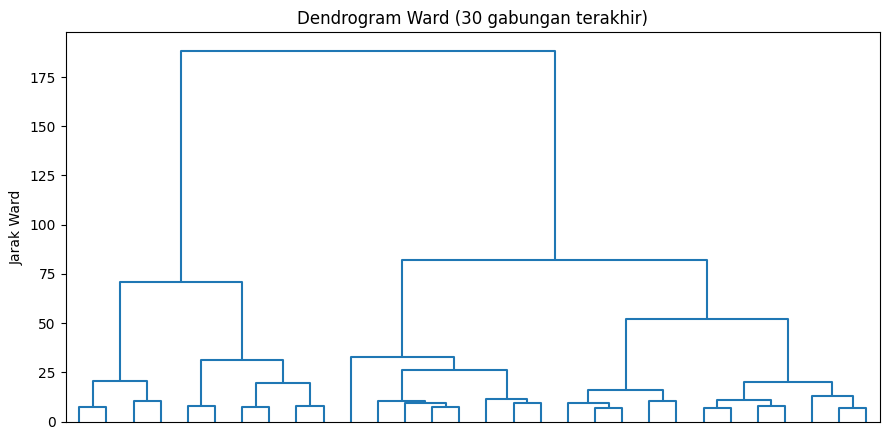

Tinggi 5 penggabungan terakhir: [ 32.6  52.   70.9  82.2 188.3]


In [67]:
# Dendrogram (Ward)
Lk = linkage(X, method="ward")
plt.figure(figsize=(9, 4.5))
dendrogram(Lk, truncate_mode="lastp", p=30, no_labels=True, color_threshold=0)
plt.title("Dendrogram Ward (30 gabungan terakhir)"); plt.ylabel("Jarak Ward")
plt.tight_layout(); plt.savefig("figures/p3_dendrogram.png", dpi=150); plt.show()
print("Tinggi 5 penggabungan terakhir:", Lk[-5:, 2].round(1))

Gambar di atas menampilkan dendrogram dari Hierarchical Clustering dengan metode linkage Ward yang dipotong pada 30 penggabungan terakhir agar struktur percabangannya tetap terbaca dengan jelas. Nilai jarak (tinggi) untuk lima penggabungan terakhir turut dicetak secara berurutan, yakni 32,6; 52,0; 70,9; 82,2; dan 188,3. Lonjakan jarak terbesar terjadi tepat pada penggabungan paling akhir yaitu dari 82,2 ke 188,3 yang mengindikasikan bahwa data secara alami terbagi menjadi dua kelompok utama dan semakin memperkuat pemilihan jumlah klaster optimal k=2.

In [68]:
# Pilih k final
k_opt = int(metrik["K-means"]["k"][int(np.argmax(metrik["K-means"]["silhouette"]))])
print("k optimal (silhouette K-means):", k_opt)

umur = pd.cut(df["Rings"], bins=[0, 8, 10, 40], labels=["Muda (<=8)", "Sedang (9-10)", "Tua (>=11)"])
dewasa = np.where(df["Sex"] == "I", "I", "Dewasa(M/F)")

k optimal (silhouette K-means): 2


Jumlah klaster optimal dipilih secara otomatis berdasarkan *silhouette score* tertinggi pada *K-means* sehingga hasil yang diberikan yaitu k = 2, dimana Davies-Bouldin dan dendrogram juga memberikan hasil yang sama.

In [69]:
def evaluasi(k):
    out = {}
    for nama in metrik:
        lab = label[(nama, k)]
        out[nama] = {
            "silhouette": silhouette_score(X, lab),
            "ARI_Sex": adjusted_rand_score(df["Sex"], lab), "NMI_Sex": normalized_mutual_info_score(df["Sex"], lab),
            "ARI_Dewasa": adjusted_rand_score(dewasa, lab),
            "ARI_Umur": adjusted_rand_score(umur, lab), "NMI_Umur": normalized_mutual_info_score(umur, lab),
            "ukuran": np.bincount(lab).tolist(),
        }
        out[nama]["tab_sex"] = pd.crosstab(lab, df["Sex"]).to_dict()
        out[nama]["tab_umur"] = pd.crosstab(lab, umur).to_dict()
        out[nama]["rings_rata"] = df.groupby(lab)["Rings"].mean().round(2).tolist()
    return out

Fungsi evaluasi didefinisikan untuk membandingkan hasil pengelompokan dengan label aktual melalui beberapa ukuran kesesuaian dan distribusi. Metrik Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) digunakan untuk mengukur tingkat keselarasan klaster dengan label sebenarnya, di mana nilai mendekati 1 menandakan kesesuaian yang sangat tinggi, sedangkan nilai mendekati 0 menunjukkan pembagian yang hampir acak. Selain itu, fungsi tersebut juga menghitung ukuran masing-masing klaster, menyusun tabel silang (crosstab) antara klaster dengan variabel Sex serta kategori usia, dan menghitung rata-rata jumlah Rings pada tiap klaster.

In [70]:
eval_hasil = {}
for k in sorted({2, 3, k_opt}):
    eval_hasil[k] = evaluasi(k)
    print(f"\n===== k = {k} =====")
    for nama, e in eval_hasil[k].items():
        print(nama, {a: (round(b, 3) if isinstance(b, float) else b) for a, b in e.items()
                     if a not in ("tab_sex", "tab_umur")})
        print(pd.crosstab(label[(nama, k)], df["Sex"]).to_string())
        print(pd.crosstab(label[(nama, k)], umur).to_string())


===== k = 2 =====
K-means {'silhouette': np.float64(0.513), 'ARI_Sex': 0.184, 'NMI_Sex': np.float64(0.169), 'ARI_Dewasa': 0.269, 'ARI_Umur': 0.202, 'NMI_Umur': np.float64(0.181), 'ukuran': [1940, 2235], 'rings_rata': [8.32, 11.34]}
Sex      F     I     M
row_0                 
0      334  1138   468
1      973   202  1060
Rings  Muda (<=8)  Sedang (9-10)  Tua (>=11)
row_0                                       
0            1186            435         319
1             219            888        1128
Spectral {'silhouette': np.float64(0.446), 'ARI_Sex': 0.09, 'NMI_Sex': np.float64(0.136), 'ARI_Dewasa': 0.289, 'ARI_Umur': 0.111, 'NMI_Umur': np.float64(0.179), 'ukuran': [3324, 851], 'rings_rata': [10.73, 6.85]}
Sex       F    I     M
row_0                 
0      1249  697  1378
1        58  643   150
Rings  Muda (<=8)  Sedang (9-10)  Tua (>=11)
row_0                                       
0             695           1221        1408
1             710            102          39
Hierarchic

**Penjelasan:** Fungsi evaluasi dijalankan untuk k = 2 dan k = 3. Pada k = 2, tingkat kesesuaian klaster terhadap `Sex` tergolong rendah dengan ARI maksimum 0,184, sedangkan terhadap pemisahan label *infant* dan dewasa sedikit lebih tinggi yaitu 0,27–0,29. Hasil tabel silang mengonfirmasi bahwa abalone jantan dan betina bercampur merata di seluruh klaster, sedangkan klaster dengan ukuran lebih kecil didominasi oleh kelompok infant dan abalone muda yang memiliki rata-rata nilai Rings lebih rendah. Secara khusus, pada algoritma Spectral Clustering klaster kecil (berisi 851 sampel) menunjukkan tingkat kemurnian tertinggi meski hanya menjaring sebagian populasi infant.

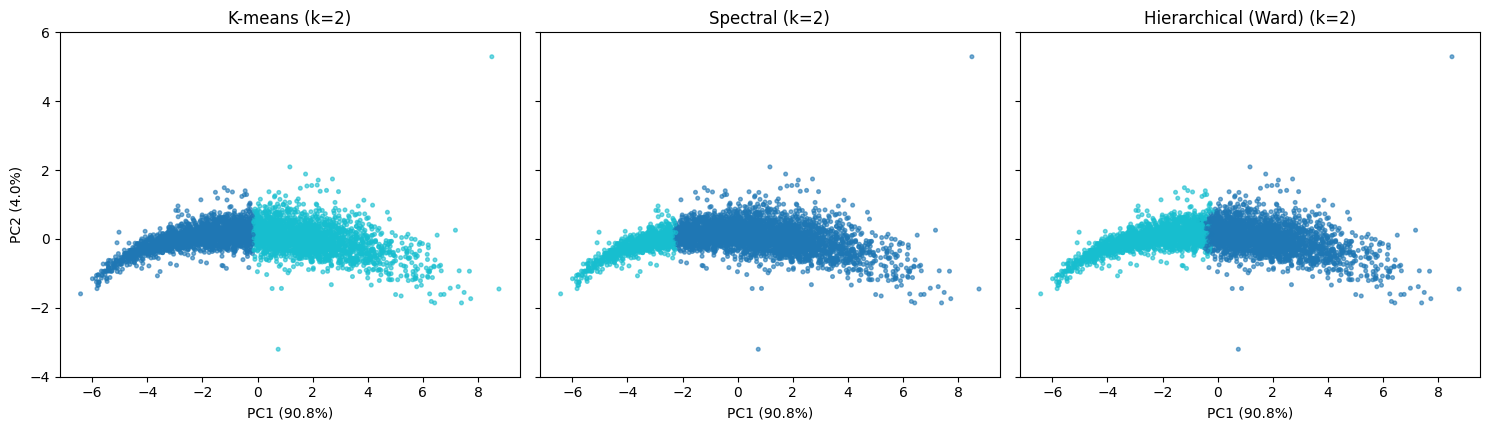

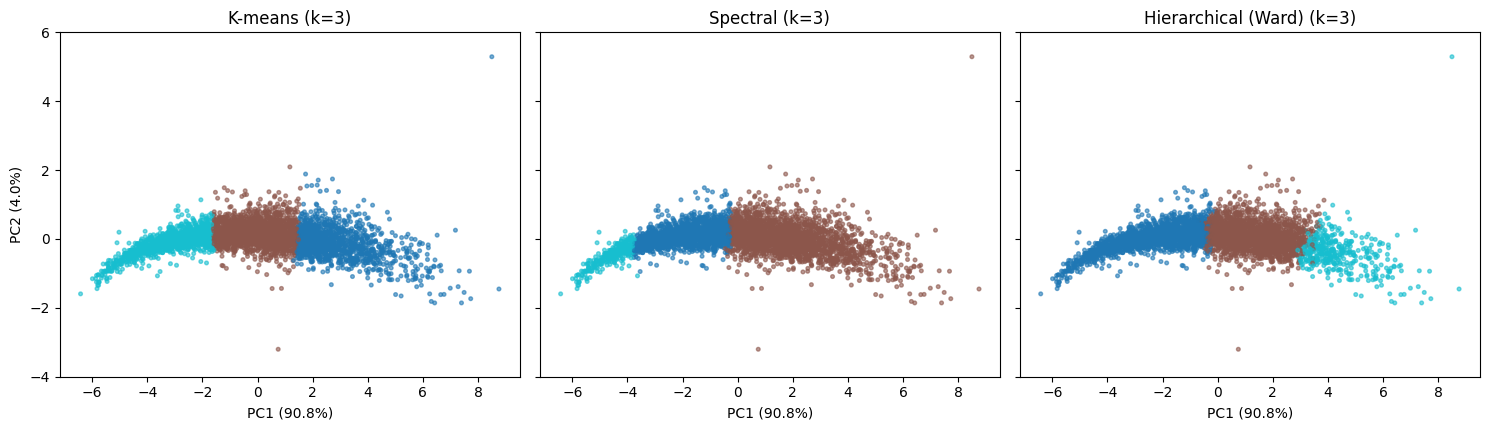

In [71]:
# Visualisasi klaster pada bidang PCA, untuk k_opt dan k=3
for k in sorted({k_opt, 3}):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
    for ax, nama in zip(axes, metrik):
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=label[(nama, k)], cmap="tab10", s=7, alpha=0.6)
        ax.set_ylim(-4, 6); ax.set_title(f"{nama} (k={k})"); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.tight_layout(); plt.savefig(f"figures/p3_klaster_k{k}.png", dpi=150); plt.show()

Gambar di atas menampilkan visualisasi klaster pada bidang dua komponen utama (PCA) untuk jumlah klaster optimal k=2 dan skenario pembanding k=3, dengan satu panel untuk setiap algoritma dan pewarnaan yang membedakan keanggotaan klaster. Rentang sumbu vertikal dibatasi pada interval 4 hingga 6 agar observasi pencilan ekstrem (Height = 1,13) yang terletak jauh di luar sebaran utama tidak mendistorsi skala tampilan plot. Secara visual, klaster-klaster yang terbentuk tampak seperti potongan dari satu sebaran data yang memanjang di sepanjang sumbu ukuran fisik, alih-alih kelompok terpisah yang saling terisolasi.

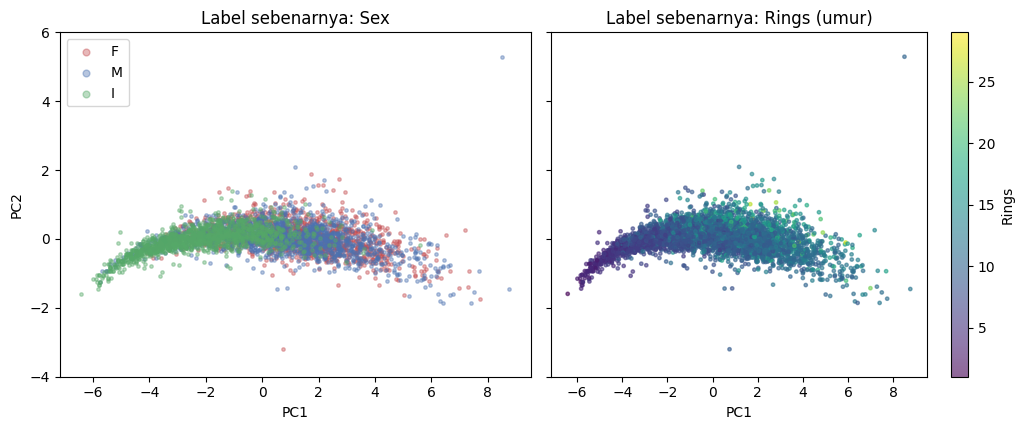

In [72]:
# Label sebenarnya pada bidang PCA
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharex=True, sharey=True)
for s, c in zip(["F", "M", "I"], ["#C44E52", "#4C72B0", "#55A868"]):
    m = df["Sex"] == s; axes[0].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.4, c=c, label=s)
axes[0].legend(markerscale=2); axes[0].set_title("Label sebenarnya: Sex")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=df["Rings"], cmap="viridis", s=6, alpha=0.6)
plt.colorbar(sc, ax=axes[1], label="Rings"); axes[1].set_title("Label sebenarnya: Rings (umur)")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylim(-4, 6)
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.savefig("figures/p3_label_sebenarnya.png", dpi=150); plt.show()

json.dump({"metrik": metrik, "inertia": inertia, "k_opt": k_opt,
           "pca_var": pca_full.explained_variance_ratio_.tolist(),
           "evaluasi": {str(k): v for k, v in eval_hasil.items()}},
          open("results/part3.json", "w"), indent=2, default=float)

Sebagai pembanding, titik pada bidang PCA yang sama diwarnai dengan label sebenarnya, yaitu `Sex` di panel kiri dan `Rings` di panel kanan. Visualisasi tersebut menunjukkan bahwa titik-titik untuk kategori jantan dan betina saling bertumpuk secara merata, sementara kelompok infant terkonsentrasi di ujung rentang ukuran kecil. Selain itu, jumlah `Rings` meningkat secara bertahap seiring bertambahnya ukuran fisik.

###Pembahasan

Tidak satu pun algoritma pengelompokan menghasilkan klaster yang selaras dengan kategori Sex (nilai ARI maksimum hanya 0,184). Temuan ini konsisten dengan hasil analisis pada Bagian 1, abalone jantan dan betina tidak dapat dibedakan berdasarkan ukuran fisik, sehingga keduanya tercampur dalam proporsi yang hampir seimbang di setiap klaster. Struktur yang berhasil ditangkap oleh algoritma justru adalah pemisahan antara fase infant dan dewasa, yang sejalan dengan perbedaan usia muda dan tua. Hal ini ditunjukkan oleh nilai ARI terhadap label biner infant–dewasa yang lebih tinggi (0,27–0,29) dibandingkan terhadap tiga kelas Sex, serta rata-rata jumlah Rings yang jauh lebih rendah pada klaster berukuran kecil.
Meskipun demikian, kesesuaian tersebut tergolong lemah karena nilai ARI di bawah 0,3 menandakan masih banyak abalone dewasa muda yang masuk ke klaster "kecil" maupun sebaliknya, bahkan klaster yang didominasi oleh 59% infant tetap memuat 41% individu non-infant. Pada k=3, K-means membentuk klaster terkecil berisi 1.163 abalone (rata-rata 7,33 cincin) yang terdiri atas 71% infant dan 77% abalone muda. Sementara itu, spectral clustering menghasilkan klaster sangat kecil beranggotakan 301 abalone (rata-rata 5,51 cincin) yang didominasi oleh infant (82%) dan abalone muda (96%), tetapi hanya mampu menjaring sebagian kecil dari total populasi infant. Dengan kata lain, tidak terbentuk satu pun klaster yang murni merepresentasikan kategori Sex tertentu.
Ditinjau dari perilaku algoritmanya, K-means dan Ward memberikan hasil yang hampir sama pada k=2 (keduanya mencatatkan koefisien silhouette 0,513 serta nilai ARI yang mirip terhadap label asli). Sebaliknya, spectral clustering dengan graf tetangga terdekat bekerja berdasarkan konektivitas lokal, sehingga cenderung memisahkan ujung sebaran data yang berkepadatan rendah dan menghasilkan ukuran klaster yang tidak seimbang (851 berbanding 3.324). Meskipun klaster kecil hasil spectral clustering memiliki tingkat kemurnian biologis paling tinggi, nilai indeks silhouette dan Calinski-Harabasz-nya lebih rendah karena kedua metrik evaluasi tersebut lebih menyukai klaster yang padat dan berbentuk cembung.

Pemilihan algoritma yang paling sesuai bergantung pada tujuan analisis. Berdasarkan metrik validasi internal dan efisiensi komputasi, K-means atau Ward lebih cocok diterapkan pada struktur data ini karena keduanya cepat, stabil, dan konsisten satu sama lain. Metode Ward unggul karena menyediakan dendrogram yang secara visual mendukung pemilihan k=2, sedangkan K-means lebih hemat secara komputasi untuk ukuran dataset yang lebih besar. Di sisi lain, keunggulan spectral clustering dalam menangani klaster non-cembung atau berkepadatan heterogen tidak termanfaatkan secara optimal karena data abalone tidak memiliki celah pemisah antarkelompok, sementara beban komputasinya jauh lebih tinggi (memerlukan pembentukan matriks afinitas dan dekomposisi eigen). Sebagai kesimpulan utama, data abalone ini lebih tepat dipandang sebagai sebuah kontinum pertumbuhan daripada kelompok-kelompok yang terpisah secara diskret, sehingga hasil pengelompokan yang terbentuk sebaiknya dimaknai sebagai gradasi ukuran ("kecil, sedang, besar") dan bukan sebagai kategori biologis.